# 03 Stage 1: monsoon risk regions by clustering

Groups the 77 districts into risk regions from their 2017 to 2022 profile only (objective 1).
The profile holds the monthly rate of damaging days per hazard (4 x 7), the monthly ERA5 rain
climatology (7) and two terrain values (37 columns). It is standardised and reduced by PCA, then
clustered with K-means, Ward agglomerative clustering and a Gaussian mixture model. Validity is
judged with the silhouette, Davies-Bouldin and Calinski-Harabasz indices, BIC for the mixture,
bootstrap stability (adjusted Rand index over resampled seasons) and agreement with the
ecological belts (elevation proxy) and the provinces. The chosen regions are encoded three ways
for Stage 2: the hard label, the GMM posterior probabilities and the distances to the K-means centroids.

- **Inputs:** `data/processed/feature-matrix.parquet` (notebook 01), `data/processed/district-terrain.csv`,
  the BIPAD district table and district polygons in `data/raw/`
- **Outputs:** `data/processed/district-regions.csv` (read by notebook 04), `results/cluster-*.csv`,
  `results/region-profiles.csv`; figures `fig-cluster-validity`, `fig-region-profiles` and
  `fig-region-map` in `paper/figures/`
- **Runtime:** about 10 seconds

## Setup

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the repository root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

from src import config as C
from src import plotting as PL
from src import regions as R
from src.geography import districts
from src.weather import load_terrain

PL.setup()
F = pd.read_parquet(C.PROCESSED / "feature-matrix.parquet")
T = load_terrain().set_index("district")
D = districts().set_index("district")
print("seed", C.SEED, "profile seasons", C.TRAIN_SEASONS)

seed 42 profile seasons [2017, 2018, 2019, 2020, 2021, 2022]


## 1. District profile, standardisation and PCA

With 77 districts and 37 standardised columns, the first four components carry about half of the
variance and each later one adds less than 6%. The main analysis uses those four components; the
90%-of-variance space (19 components) is kept as a sensitivity check, because in that space the
diagonal GMM degenerates into singleton components and every index drops (section 3).

In [2]:
prof = R.district_profile(F, C.TRAIN_SEASONS)
assert prof.shape == (77, 37) and prof.notna().all().all()
Z_all, scaler, pca = R.reduce(prof, variance=0.999)
ratio = pca.explained_variance_ratio_
N_PC = 4
N_PC_90 = int(np.searchsorted(np.cumsum(ratio), 0.90) + 1)
Z, Z90 = Z_all[:, :N_PC], Z_all[:, :N_PC_90]
print(
    f"explained variance by component: {np.round(ratio[:8], 3)}; first {N_PC} carry {ratio[:N_PC].sum():.2f}; {N_PC_90} components reach 90%"
)
load = pd.DataFrame(
    pca.components_[:N_PC].T, index=prof.columns, columns=[f"PC{i + 1}" for i in range(N_PC)]
)
for c in load.columns:
    top = load[c].abs().sort_values(ascending=False).head(5).index
    print(f"{c}: " + ", ".join(f"{k} ({load.loc[k, c]:+.2f})" for k in top))
load.round(3).to_csv(C.RESULTS / "cluster-pca-loadings.csv")

explained variance by component: [0.213 0.123 0.089 0.061 0.053 0.046 0.038 0.035]; first 4 carry 0.49; 19 components reach 90%
PC1: rain_m8 (+0.31), rain_m6 (+0.30), rain_m4 (+0.30), rain_m5 (+0.30), rain_m7 (+0.29)
PC2: rate_lightning_m6 (+0.35), rate_lightning_m7 (+0.34), rate_lightning_m5 (+0.31), elev_mean (-0.30), rate_flood_m7 (+0.29)
PC3: rate_lightning_m8 (+0.31), rate_heavy_rain_m9 (-0.30), rate_landslide_m8 (+0.28), rate_heavy_rain_m7 (-0.27), rate_lightning_m5 (+0.24)
PC4: rate_heavy_rain_m8 (+0.40), rate_heavy_rain_m9 (+0.31), rate_heavy_rain_m7 (+0.29), rate_landslide_m6 (+0.28), rate_landslide_m8 (+0.27)


## 2. Validity indices for k = 2 to 8

method  k  silhouette  davies_bouldin  calinski_harabasz  smallest_cluster      bic space
kmeans  2       0.279           1.355             32.063                37      NaN 4 PCs
kmeans  3       0.276           1.210             31.851                23      NaN 4 PCs
kmeans  4       0.318           1.022             33.619                 9      NaN 4 PCs
kmeans  5       0.310           1.067             34.045                 8      NaN 4 PCs
kmeans  6       0.327           0.932             34.584                 6      NaN 4 PCs
kmeans  7       0.328           0.886             35.131                 3      NaN 4 PCs
kmeans  8       0.330           0.876             34.093                 2      NaN 4 PCs
  ward  2       0.272           1.361             30.782                34      NaN 4 PCs
  ward  3       0.264           1.177             30.826                20      NaN 4 PCs
  ward  4       0.308           1.011             32.454                 9      NaN 4 PCs
  ward  5 

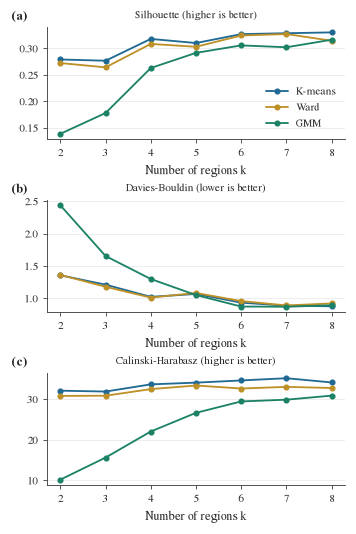

In [3]:
vt = R.validity_table(Z)
vt["space"] = f"{N_PC} PCs"
vt90 = R.validity_table(Z90)
vt90["space"] = f"{N_PC_90} PCs (90% variance)"
validity = pd.concat([vt, vt90], ignore_index=True)
validity.round(3).to_csv(C.RESULTS / "cluster-validity.csv", index=False)
print(vt.round(3).to_string(index=False))

f, axes = PL.fig(width=PL.COL_W, height=5.4, nrows=3)
f.subplots_adjust(hspace=0.55)
for i_ax, (ax, metric, label) in enumerate(
    zip(
        axes,
        ["silhouette", "davies_bouldin", "calinski_harabasz"],
        [
            "Silhouette (higher is better)",
            "Davies-Bouldin (lower is better)",
            "Calinski-Harabasz (higher is better)",
        ],
    )
):
    PL.letter(ax, "abc"[i_ax])
    for i, m in enumerate(["kmeans", "ward", "gmm"]):
        d = vt[vt["method"] == m]
        ax.plot(
            d["k"],
            d[metric],
            marker="o",
            ms=3,
            label={"kmeans": "K-means", "ward": "Ward", "gmm": "GMM"}[m],
            color=PL.OKABE_MUTED[i],
        )
    ax.set_xlabel("Number of regions k")
    ax.set_title(label, fontsize=7)
axes[0].legend()
PL.save(f, "fig-cluster-validity")

## 3. Choosing k and the method

Rule, fixed before looking at Stage 2: among K-means solutions whose smallest region has at least
five districts, take the k with the best silhouette, breaking ties with Davies-Bouldin. Ward and
the GMM are compared at the same k. BIC for the GMM is reported but a diagonal mixture on 77
points favours few components, so it is not used to choose k on its own.

In [4]:
ok = vt[(vt["method"] == "kmeans") & (vt["smallest_cluster"] >= 5)].sort_values(
    ["silhouette", "davies_bouldin"], ascending=[False, True]
)
K = int(ok.iloc[0]["k"])
print(f"chosen k = {K}")
km, lab_km = R.fit_clusterer("kmeans", Z, K)
_, lab_ward = R.fit_clusterer("ward", Z, K)
gm, lab_gmm = R.fit_clusterer("gmm", Z, K)
_, lab_km90 = R.fit_clusterer("kmeans", Z90, K)
bic = vt[vt["method"] == "gmm"].set_index("k")["bic"]
print("GMM BIC by k:", bic.round(0).to_dict(), "-> BIC minimum at k =", int(bic.idxmin()))
print(
    "agreement between methods (ARI): K-means vs Ward %.2f, K-means vs GMM %.2f, Ward vs GMM %.2f, K-means 4 PCs vs 19 PCs %.2f"
    % (
        adjusted_rand_score(lab_km, lab_ward),
        adjusted_rand_score(lab_km, lab_gmm),
        adjusted_rand_score(lab_ward, lab_gmm),
        adjusted_rand_score(lab_km, lab_km90),
    )
)
print("region sizes (K-means):", np.bincount(lab_km).tolist())

chosen k = 6
GMM BIC by k: {2: 1342.0, 3: 1340.0, 4: 1355.0, 5: 1371.0, 6: 1380.0, 7: 1372.0, 8: 1405.0} -> BIC minimum at k = 3
agreement between methods (ARI): K-means vs Ward 0.75, K-means vs GMM 0.73, Ward vs GMM 0.67, K-means 4 PCs vs 19 PCs 0.94
region sizes (K-means): [9, 6, 12, 20, 23, 7]


## 4. Stability and agreement with belts and provinces

Bootstrap: the six training seasons are resampled with replacement 200 times, the profile is
rebuilt from the sample, the pipeline is refitted and the adjusted Rand index against the
reference labels is recorded. Belts come from elevation (`regions.belts`: Mountain if the mean
ward elevation is at least 1,700 m and at least 5% of wards lie above 3,000 m; Terai if the mean
is below 700 m and fewer than 15% of wards lie above 1,000 m; Hill otherwise).

In [5]:
belt = R.belts(T).reindex(prof.index)
prov = D["province"].reindex(prof.index)
rows = []
for m, lab in (("kmeans", lab_km), ("ward", lab_ward), ("gmm", lab_gmm)):
    ari = R.bootstrap_ari(F, C.TRAIN_SEASONS, m, K, lab, n_boot=200)
    rows.append(
        {
            "method": m,
            "k": K,
            "boot_ari_mean": ari.mean(),
            "boot_ari_q05": np.quantile(ari, 0.05),
            "boot_ari_q95": np.quantile(ari, 0.95),
            "ari_vs_belts": adjusted_rand_score(belt, lab),
            "ari_vs_provinces": adjusted_rand_score(prov, lab),
        }
    )
stab = pd.DataFrame(rows)
stab.round(3).to_csv(C.RESULTS / "cluster-stability.csv", index=False)
print(stab.round(3).to_string(index=False))
print(pd.crosstab(belt, lab_km, rownames=["belt"], colnames=["K-means region"]))

method  k  boot_ari_mean  boot_ari_q05  boot_ari_q95  ari_vs_belts  ari_vs_provinces
kmeans  6          0.549         0.366         0.729         0.241             0.223
  ward  6          0.472         0.302         0.653         0.225             0.244
   gmm  6          0.215         0.049         0.461         0.249             0.216
K-means region  0  1   2   3   4  5
belt                               
Hill            4  3   0   6  19  5
Mountain        0  3   0  12   3  1
Terai           5  0  12   2   1  1


## 5. Region profiles and map

In [6]:
reg = pd.Series(lab_km, index=prof.index, name="region")
tr = F[F["season"].isin(C.TRAIN_SEASONS)].merge(reg, left_on="district", right_index=True)
te = F[F["split"] == "test"].merge(reg, left_on="district", right_index=True)
HAZ = list(C.HAZARDS.values())
profile = pd.DataFrame(
    {
        "districts": reg.value_counts().sort_index(),
        "elev_mean_m": T["elev_mean"].groupby(reg).mean(),
        "rain_mm_per_day": tr.groupby("region")["rain_1d"].mean(),
        "rain_jul_aug_mm_per_day": tr[tr["month"].isin([7, 8])].groupby("region")["rain_1d"].mean(),
        **{f"damaging_{h}_pct": tr.groupby("region")[f"day_{h}"].mean() * 100 for h in HAZ},
        "y_rate_train_pct": tr.groupby("region")["y"].mean() * 100,
        "y_rate_test_pct": te.groupby("region")["y"].mean() * 100,
        "belts": belt.groupby(reg).agg(
            lambda s: ", ".join(f"{k} {v}" for k, v in s.value_counts().items())
        ),
    }
)
profile.index.name = "region"
profile.round(2).to_csv(C.RESULTS / "region-profiles.csv")
print(profile.round(2).to_string())
print("members:")
for r in sorted(reg.unique()):
    print(f"  region {r}: " + ", ".join(sorted(reg[reg == r].index)))

        districts  elev_mean_m  rain_mm_per_day  rain_jul_aug_mm_per_day  damaging_flood_pct  damaging_landslide_pct  damaging_heavy_rain_pct  damaging_lightning_pct  y_rate_train_pct  y_rate_test_pct                         belts
region                                                                                                                                                                                                                                
0               9       463.29             9.12                    15.98                0.84                    0.42                     0.35                    2.20              9.58             9.22               Terai 5, Hill 4
1               6      1719.74            19.24                    30.61                0.22                    1.33                     0.45                    1.03              7.68            10.70            Hill 3, Mountain 3
2              12       164.45             7.23                    13.27    

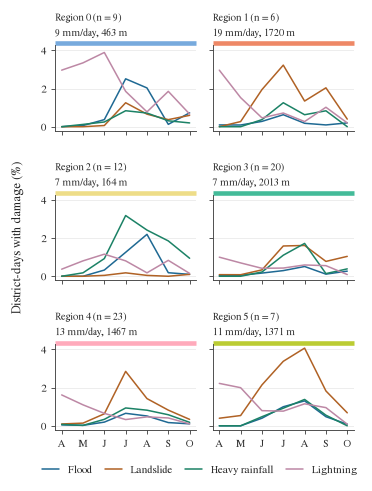

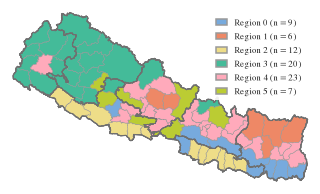

In [7]:
# Monthly damaging-day rate per hazard, by region.
f, axes = PL.fig(width=PL.COL_W, height=4.6, nrows=3, ncols=2, sharey=True, sharex=True)
f.subplots_adjust(hspace=0.75, wspace=0.12, bottom=0.12)
axes = axes.ravel()
for r, ax in zip(sorted(reg.unique()), np.atleast_1d(axes)):
    d = tr[tr["region"] == r].groupby("month")[[f"day_{h}" for h in HAZ]].mean() * 100
    for h in HAZ:
        ax.plot(d.index, d[f"day_{h}"], color=PL.HAZARD_COL[h], label=PL.HAZARD_NAME[h], lw=1)
    ax.set_title(
        f"Region {r} (n = {profile.loc[r, 'districts']})\n{profile.loc[r, 'rain_mm_per_day']:.0f} mm/day, {profile.loc[r, 'elev_mean_m']:.0f} m",
        fontsize=6.5,
        loc="left",
    )
    ax.plot(
        [0, 1],
        [1.02, 1.02],
        transform=ax.transAxes,
        color=PL.REGION_COL[r],
        lw=3,
        clip_on=False,
        solid_capstyle="butt",
    )
    ax.set_xticks(range(4, 11))
    ax.set_xticklabels(list("AMJJASO"))
f.supylabel("District-days with damage (%)", fontsize=8, x=0.01)
handles, labels = axes[0].get_legend_handles_labels()
f.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    fontsize=7,
    frameon=False,
    bbox_to_anchor=(0.5, 0.01),
    columnspacing=1.2,
    handlelength=1.6,
)
PL.save(f, "fig-region-profiles")

f, ax = PL.fig(width=PL.COL_W, height=2.1)
PL.categorical_map(
    ax,
    reg,
    {r: PL.REGION_COL[r] for r in sorted(reg.unique())},
    {r: f"Region {r} (n = {profile.loc[r, 'districts']})" for r in sorted(reg.unique())},
)
PL.save(f, "fig-region-map")

## 6. Region encodings for Stage 2

Saved to `data/processed/district-regions.csv`: the K-means label, the GMM posterior
probabilities and the distances to the K-means centroids, plus the belt and province for the
error analysis. Everything here was fitted on 2017 to 2022 only.

In [8]:
enc = R.region_encodings(Z, prof.index, km, gm).set_index("district")
enc["belt"] = belt
enc["province"] = prov
enc["region_ward"] = lab_ward
enc["region_gmm"] = lab_gmm
enc.to_csv(C.PROCESSED / "district-regions.csv")
print(enc.shape, list(enc.columns))
print(
    "mean maximum GMM posterior: %.2f; districts with max posterior < 0.9: %d"
    % (
        enc.filter(like="region_post_").max(axis=1).mean(),
        (enc.filter(like="region_post_").max(axis=1) < 0.9).sum(),
    )
)

(77, 17) ['region', 'region_post_0', 'region_post_1', 'region_post_2', 'region_post_3', 'region_post_4', 'region_post_5', 'region_dist_0', 'region_dist_1', 'region_dist_2', 'region_dist_3', 'region_dist_4', 'region_dist_5', 'belt', 'province', 'region_ward', 'region_gmm']
mean maximum GMM posterior: 0.96; districts with max posterior < 0.9: 10
